<a href="https://colab.research.google.com/github/Rohan46os/Video_gen_model/blob/main/diffusion_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [58]:
from torch._C import device
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [59]:
import kagglehub
path = kagglehub.dataset_download("andrewmvd/face-mask-detection")

Using Colab cache for faster access to the 'face-mask-detection' dataset.


In [60]:
path

'/kaggle/input/face-mask-detection'

In [61]:
img1_path = "/root/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1/images/maksssksksss1.png"

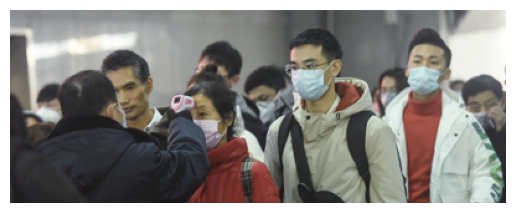

In [62]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(img1_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [63]:
from tqdm import tqdm
import os
import numpy as np
from PIL import Image

image_folder = "/root/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1/images"

vectors = []
filenames = []

files = os.listdir(image_folder)

for filename in tqdm(files):
    filepath = os.path.join(image_folder, filename)

    try:
        img = Image.open(filepath).convert("RGB")
        img = img.resize((128, 128))

        img_array = np.array(img, dtype=np.float32) / 255.0
        vectors.append(img_array.flatten())
        filenames.append(filename)

    except:
        pass

vectors = np.array(vectors)

print(vectors.shape)

100%|██████████| 853/853 [00:12<00:00, 69.34it/s]


(853, 49152)


In [64]:
import torch

X = torch.tensor(vectors, dtype=torch.float32)

# (N, 49152) → (N, 128, 128, 3)
X = X.reshape(-1, 128, 128, 3)

# (N, H, W, C) → (N, C, H, W)
X = X.permute(0, 3, 1, 2)

print(X.shape)

torch.Size([853, 3, 128, 128])


In [65]:
vectors.shape

(853, 49152)

In [66]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [67]:
dataset

**Now bulding a VAE which will predict MEAN and VARIANCE**

Building a cnn VAE encoder which predicts the mean and variance of all the vectors


In [68]:
##This is an encoder which encodes input vector into latent space by producing mean and variance

import torch
import torch.nn as nn


class Encoder(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()

        self.encoder = nn.Sequential(
            # [B, 3, 128, 128]
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 64, 64, 64]
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 128, 32, 32]
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )

        # Produce mean and log-variance
        self.mu = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

        self.logvar = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

    def forward(self, x):
        h = self.encoder(x)

        mu = self.mu(h)
        logvar = self.logvar(h)

        return mu, logvar

In [69]:
model = Encoder()

x = torch.randn(32, 3, 128, 128)

mu, logvar = model(x)

print("input   :", x.shape) # (32, 49152)
print("mu      :", mu.shape) #(32, 4096)
print("logvar  :", logvar.shape) #(32, 4096)

input   : torch.Size([32, 3, 128, 128])
mu      : torch.Size([32, 4, 32, 32])
logvar  : torch.Size([32, 4, 32, 32])


In [70]:
std  =torch.randn_like(logvar*5) #

z = mu + torch.exp(logvar/2)*torch.randn_like(logvar) # these are latent vecors of inputs


print(z.shape)

torch.Size([32, 4, 32, 32])


logvar

   ↓
   
  exp()

variance

   ↓

  sqrt()

standard deviation

   ↓

μ + σ ε

   ↓

z

In [71]:

std.shape

torch.Size([32, 4, 32, 32])

Decoder

In [72]:
##This is a decoder which converts latent vector into image

import torch
import torch.nn as nn

class Decoder(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()

        self.decoder = nn.Sequential(
            # [B, 4, 32, 32]
            nn.ConvTranspose2d(
                latent_channels, 64,
                kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            # [B, 64, 64, 64]
            nn.ConvTranspose2d(
                64, 32,
                kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            # [B, 32, 128, 128]
            nn.Conv2d(
                32, 3,
                kernel_size=3, stride=1, padding=1
            ),

            # Match the input's [0, 1] pixel range
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.decoder(z)

In [73]:
decoder = Decoder()


x_hat = decoder(z)

print(x_hat.shape)

torch.Size([32, 3, 128, 128])


In [74]:




recon_loss = F.mse_loss(x_hat, x)
recon_loss # This loss to minimize the distance between actual vector and predicted vector

##This is Divergence kl loss which forces the latent distribution to be close to standard normal distribution
Dkl_loss = -0.5 * torch.sum(
    1 + logvar - mu.pow(2) - logvar.exp(),
    dim=(1, 2, 3)
).mean()

total_loss = recon_loss + Dkl_loss

In [75]:
class VAE(nn.Module):
  def __init__(self):
    super().__init__()

    self.encoder = Encoder()
    self.decoder = Decoder()

  def forward(self, x):
    mu, logvar = self.encoder(x)
    z = mu + torch.exp(logvar/2)*torch.randn_like(logvar)
    x_hat = self.decoder(z)
    return x_hat, mu, logvar, z

  def vae_loss(x_hat, x, mu, logvar, beta_vae=1e-5):
  # This loss to minimize the distance between actual vector and predicted vector
  # Reconstruction loss
    recon_loss = F.mse_loss(x_hat, x, reduction="mean")

    # KL divergence, summed over latent dimensions and averaged over images
    ##This is Divergence kl loss which forces the latent distribution to be close to standard normal distribution
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=(1, 2, 3)
    ).mean()
    total_loss = recon_loss + beta_vae * kl_loss
    return total_loss, recon_loss, kl_loss



In [76]:
dataset = TensorDataset(X)

train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 767
Validation images: 86


In [77]:
model = VAE().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 50
beta_vae = 1e-5

for epoch in range(epochs):

    # ---------- Training ----------
    model.train()

    train_total = 0.0
    train_recon = 0.0
    train_kl = 0.0

    for (images,) in train_loader:
        images = images.to(device)

        # Forward pass
        x_hat, mu, logvar, z = model(images)

        # Calculate loss
        loss, recon_loss, kl_loss = VAE.vae_loss(
            x_hat, images, mu, logvar, beta_vae
        )

        # Backpropagation
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        train_total += loss.item() * batch_size
        train_recon += recon_loss.item() * batch_size
        train_kl += kl_loss.item() * batch_size

    n_train = len(train_dataset)

    train_total /= n_train
    train_recon /= n_train
    train_kl /= n_train

    # ---------- Validation ----------
    model.eval()

    val_total = 0.0
    val_recon = 0.0
    val_kl = 0.0

    with torch.no_grad():
        for (images,) in val_loader:
            images = images.to(device)

            x_hat, mu, logvar, z = model(images)

            loss, recon_loss, kl_loss = VAE.vae_loss(
                x_hat, images, mu, logvar, beta_vae
            )

            batch_size = images.size(0)
            val_total += loss.item() * batch_size
            val_recon += recon_loss.item() * batch_size
            val_kl += kl_loss.item() * batch_size

    n_val = max(len(val_dataset), 1)

    val_total /= n_val
    val_recon /= n_val
    val_kl /= n_val

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train: {train_total:.4f} "
        f"(Recon: {train_recon:.4f}, KL: {train_kl:.2f}) | "
        f"Val: {val_total:.4f} "
        f"(Recon: {val_recon:.4f}, KL: {val_kl:.2f})"
    )

  # Epoch [100/100] Train: 0.0510 (Recon: 0.0356, KL: 154.28) | Val: 0.0511 (Recon: 0.0361, KL: 149.98)

Epoch [1/50] Train: 0.0814 (Recon: 0.0806, KL: 75.81) | Val: 0.0697 (Recon: 0.0638, KL: 586.12)
Epoch [2/50] Train: 0.0585 (Recon: 0.0530, KL: 552.71) | Val: 0.0540 (Recon: 0.0484, KL: 565.38)
Epoch [3/50] Train: 0.0500 (Recon: 0.0451, KL: 493.40) | Val: 0.0470 (Recon: 0.0422, KL: 478.44)
Epoch [4/50] Train: 0.0422 (Recon: 0.0368, KL: 534.79) | Val: 0.0362 (Recon: 0.0301, KL: 614.21)
Epoch [5/50] Train: 0.0328 (Recon: 0.0259, KL: 691.45) | Val: 0.0371 (Recon: 0.0299, KL: 725.61)
Epoch [6/50] Train: 0.0315 (Recon: 0.0246, KL: 689.95) | Val: 0.0299 (Recon: 0.0229, KL: 700.36)
Epoch [7/50] Train: 0.0293 (Recon: 0.0220, KL: 729.01) | Val: 0.0292 (Recon: 0.0215, KL: 775.61)
Epoch [8/50] Train: 0.0282 (Recon: 0.0207, KL: 753.04) | Val: 0.0280 (Recon: 0.0202, KL: 776.94)
Epoch [9/50] Train: 0.0269 (Recon: 0.0192, KL: 768.48) | Val: 0.0265 (Recon: 0.0188, KL: 772.65)
Epoch [10/50] Train: 0.0258 (Recon: 0.0180, KL: 776.88) | Val: 0.0257 (Recon: 0.0178, KL: 792.55)
Epoch [11/50] Train: 0.0253 (R

In [78]:
print(
    f"beta = {beta_vae:.8f} | "
    f"recon = {recon_loss.item():.6f} | "
    f"KL = {kl_loss.item():.4f} | "
    f"weighted KL = {(beta_vae * kl_loss.item()):.6f} | "
    f"total = {loss.item():.6f}"
)

beta = 0.00001000 | recon = 0.014219 | KL = 949.1759 | weighted KL = 0.009492 | total = 0.023711


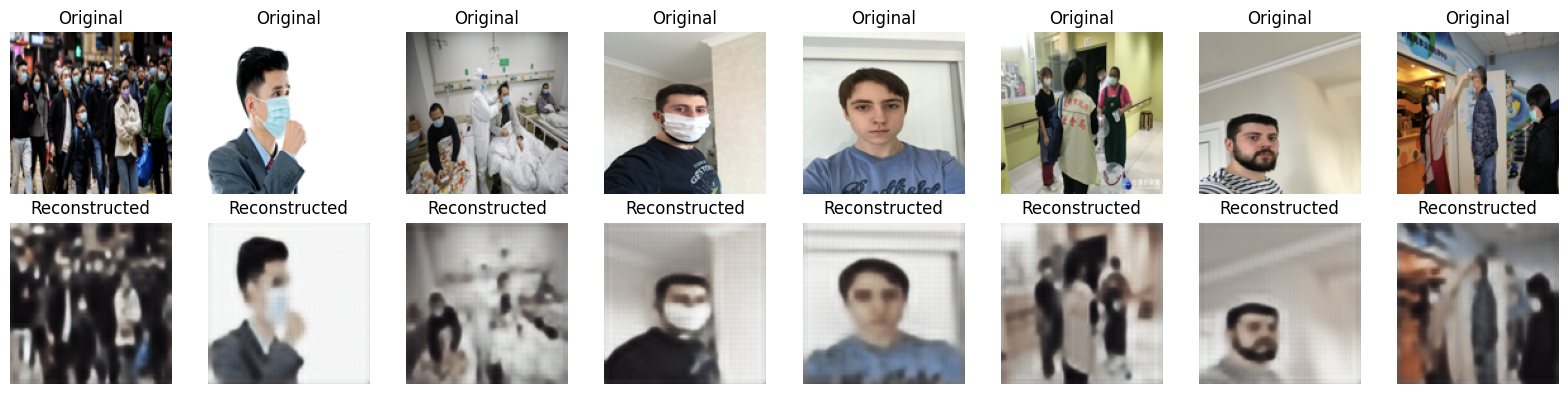

In [79]:
model.eval()

(images,) = next(iter(val_loader))
images = images[:8].to(device)

with torch.no_grad():
    # Use mu for deterministic reconstruction during this visualization
    mu, logvar = model.encoder(images)
    reconstructed = model.decoder(mu)

original = images.cpu().permute(0, 2, 3, 1).numpy()
reconstructed = reconstructed.cpu().permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(original[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].clip(0, 1))
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

VAE ends and diffusion starts

In [80]:
T = 200

betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = (1-betas)
alpha_bar = torch.cumprod(alphas, dim=0)
epsilon = torch.randn_like(z)

t = torch.randint(0, T, (z.shape[0],)) # for 32 diffirent values you select 32 different time steps

alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)

z_t = (
    torch.sqrt(alpha_bar_t) * z
    + torch.sqrt(1 - alpha_bar_t) * epsilon
)


In [81]:
print("Initial alpha_bar:", alpha_bar[0].item())
print("Final alpha_bar:", alpha_bar[-1].item())

Initial alpha_bar: 0.9998999834060669
Final alpha_bar: 0.132182776927948


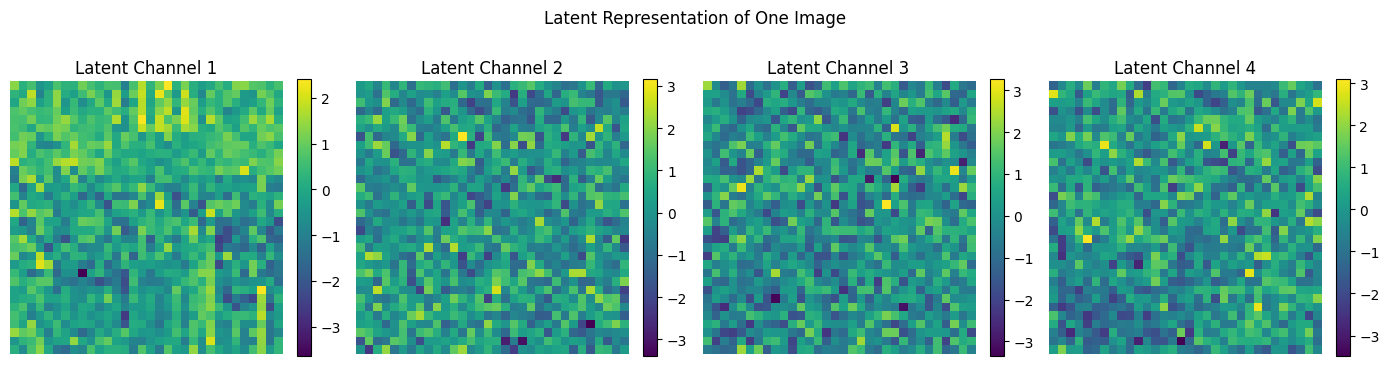

In [82]:
import matplotlib.pyplot as plt
import torch

# Take the first image in the batch
latent = z[0].detach().cpu()

fig, axes = plt.subplots(1, latent.shape[0], figsize=(14, 4))

for i in range(latent.shape[0]):
    im = axes[i].imshow(latent[i], cmap="viridis")
    axes[i].set_title(f"Latent Channel {i + 1}")
    axes[i].axis("off")
    plt.colorbar(im, ax=axes[i], fraction=0.046)

plt.suptitle("Latent Representation of One Image")
plt.tight_layout()
plt.show()

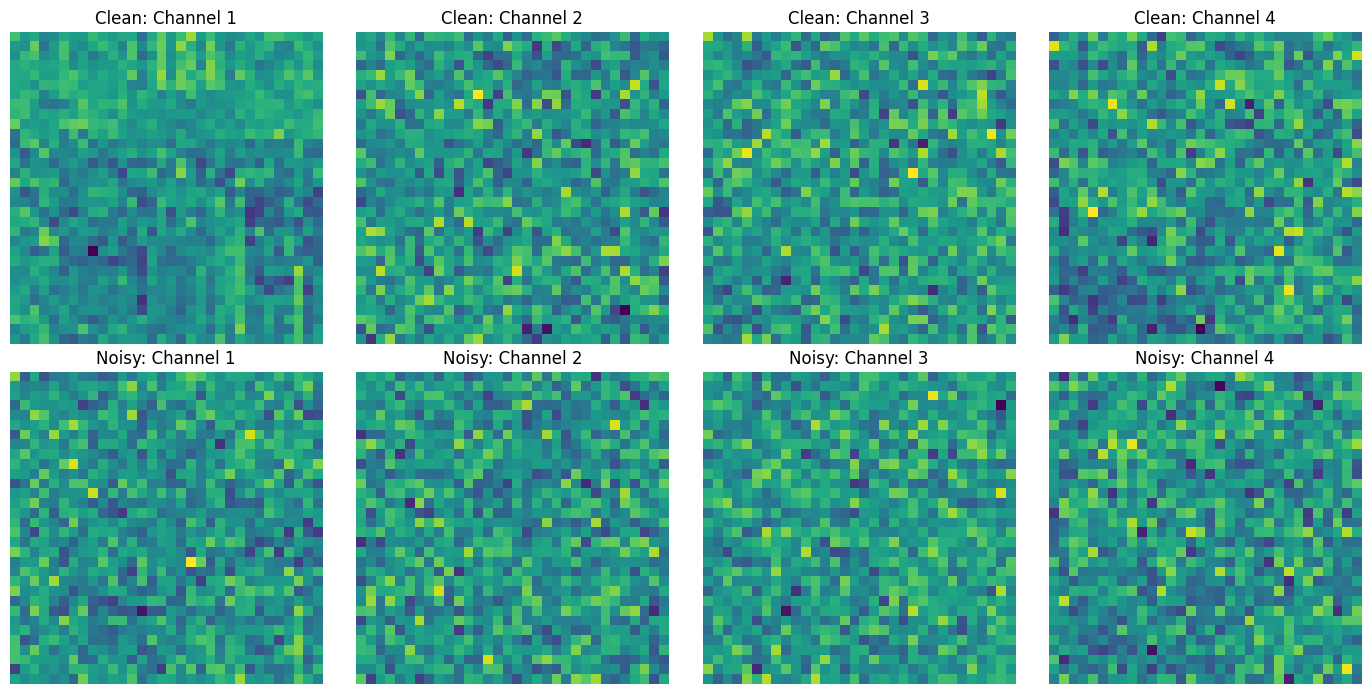

In [83]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

z0 = z[0].detach().cpu()
zt = z_t[0].detach().cpu()

# Use the same color scale for each corresponding channel
for i in range(4):
    vmin = min(z0[i].min().item(), zt[i].min().item())
    vmax = max(z0[i].max().item(), zt[i].max().item())

    axes[0, i].imshow(z0[i], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[0, i].set_title(f"Clean: Channel {i+1}")

    axes[1, i].imshow(zt[i], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[1, i].set_title(f"Noisy: Channel {i+1}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()